# From tells to Cyprus
**Instructor copy · four-hour workshop with a choice of optional lab**

An archaeological survey team has more overhead images than it can inspect carefully.
Can a model help decide which to open first? We use **50 image reviews** as a teaching
budget so that every model is compared at the same effort. This is a scenario, not
a measured limit on a real team's work.

Our initial target is a *tell*: a mound built up through repeated human occupation.
[Enki](https://zenodo.org/records/14950565) supplies image crops labelled as tell (`1`)
or non-tell/background (`0`). We use these source labels to evaluate rankings; we
do not trace site boundaries or independently verify discoveries. DINOv2 supplies one
way to turn images into numbers; the classifiers we fit are logistic regressions.

The workshop follows one decision:

1. Inspect the labelled images and their training/validation/test split.
2. Learn how precision and recall describe a shortlist.
3. Compare two image representations using validation results.
4. Inspect the chosen model's included and missed images.
5. Apply it to Cyprus imagery, where catalogue locations are not equivalent to image labels.
6. Write a recommendation, export the evidence, then assess the saved choice on test images.

### How to work through this notebook

Allow **about 3½ hours for the core path**, including discussion, a short break and
some setup support. The four-hour plan leaves about **30 minutes for one optional lab
or catch-up**. These are planning estimates for learners with basic Python and pandas;
internet or unfamiliar software can add time.

Run cells in order and pause at each exercise before running the result below it.
The main coding task is two arithmetic expressions in section 3.4; other main
exercises ask you to change one value and interpret the output. Keep brief notes for
the final recommendation rather than writing a separate report for each question.
If working alone, write a short answer in place of pair discussion.

The **optional lab is between sections 5 and 6**. Choose one activity if time permits,
or skip the whole block and continue to section 6. Optional plots start disabled.
Finish any experiments before exporting and revealing the test result.

Submit **`team_submission.zip` and your saved notebook**. The ZIP contains the ranked
Enki test CSV, settings, results and a 4–6 sentence recommendation. The notebook keeps
your exercise notes and figures. Leave `REVEAL_TEST = False` until the final debrief.

Use Jupyter or [Google Colab](https://colab.research.google.com/). Setup installs missing
packages and downloads about 73 MB of images; allow about 400 MB of disk space. No GPU,
API key or model download is needed. For an offline image load, place the facilitator's
`enki_workshop_sample.zip` in `archaeology_workshop/` before section 1's loading cell.
Dependencies must already be installed if internet is unavailable.

This copy supplies the completed expressions, optional lab plots, worked
interpretations and final test results. Participants choose one optional lab; this
copy runs both computational labs for reference. Keep it for the debrief.

## 1. Look at the images

Run the folded setup cell once, then the loading cell below the split explanation.
Setup unpacks the bundled features, Cyprus images and helper functions. Later code
uses those helpers through `workshop`; you do not need to edit the setup cell.

In [1]:
# @title Setup — run once; no edits needed
import base64, importlib.util, io, os, shutil, subprocess, sys, zipfile
from pathlib import Path

requirements = {"numpy": "numpy>=1.24,<3", "pandas": "pandas>=2.1,<4",
                "matplotlib": "matplotlib>=3.8,<4", "sklearn": "scikit-learn>=1.4,<2",
                "PIL": "pillow>=10,<14", "imagehash": "ImageHash==4.3.2",
                "requests": "requests>=2.31,<3", "tqdm": "tqdm>=4.66,<5"}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing and not os.environ.get("ARCHAEOLOGY_SKIP_INSTALL"):
    installer = ([sys.executable, "-m", "pip", "install", "-q"]
                 if importlib.util.find_spec("pip") else
                 [shutil.which("uv") or "uv", "pip", "install", "--python", sys.executable, "-q"])
    subprocess.check_call(installer + missing)

ROOT = Path(os.environ.get("ARCHAEOLOGY_WORKSHOP_ROOT", "archaeology_workshop"))
assets = ROOT / "assets"
assets.mkdir(parents=True, exist_ok=True)
ASSET_B64 = "..."
with zipfile.ZipFile(io.BytesIO(base64.b64decode(ASSET_B64))) as bundle:
    for name in bundle.namelist():
        if not (assets / name).resolve().is_relative_to(assets.resolve()):
            raise ValueError("Unsafe asset path")
    bundle.extractall(assets)
del ASSET_B64
spec = importlib.util.spec_from_file_location("workshop_helpers", assets / "workshop_helpers.py")
workshop = importlib.util.module_from_spec(spec)
spec.loader.exec_module(workshop)
print("Ready. Run the next cell to load the images.")


Ready. Run the next cell to load the images.


Our **600-image sample comes from Enki's training archive**; we create our own
teaching split within it. The release's separate test archive is not used here.
We selected 300 source-positive and 300 source-negative crops. This balance does
not estimate the frequency of tells in a real survey.

We group near-identical images, keep one per group and exclude groups with conflicting
labels. **593 images remain**. This reduces overlap from near-copies before splitting:

| Set | Images with default settings | Role |
|---|---:|---|
| Training | 200: 100 tells and 100 backgrounds | Fit both classifiers. |
| Validation | 119 | Compare the fitted classifiers and choose one. |
| Test | 119 | Assess the saved choice at the final reveal. |
| Unused | 155 | Left out to keep the training set small. |

The 100-per-class limit applies only to training. Labels for validation and test are
reserved for their respective evaluations.

**Image-size confound:** all 300 retained tell images are originally 350 × 350;
249 of the 293 negatives are 64 × 64. File size and sharpness can therefore reveal
the source label. Both feature pipelines now first resize every image to the same
**64 × 64 grid**; DINO then enlarges this common input to its required 224 × 224.
Section 3 measures the original size shortcut and checks performance within each
original size. This reduces a known shortcut, but does not equalise metres per pixel,
image rendering or all acquisition differences. Cyprus uses the same preprocessing.

**Limit of the split:** filtering similar images does not identify every repeated
site or neighbouring landscape. The sample lacks verified site or region groups, so
we cannot establish geographic independence. Keep that limitation for the final
recommendation; section 5 will examine a different setting.

Index and audit images:   0%|          | 0/600 [00:00<?, ?it/s]

600 images → 593 after filtering.


,tiles
train,200
validation,119
test,119


Original dimensions by source label (0 = negative, 1 = tell):


,label,width,height,images
0,0,64,64,249
1,0,350,350,44
2,1,350,350,300


Both feature pipelines use the same 64 × 64 input grid. Preview below shows the original images.


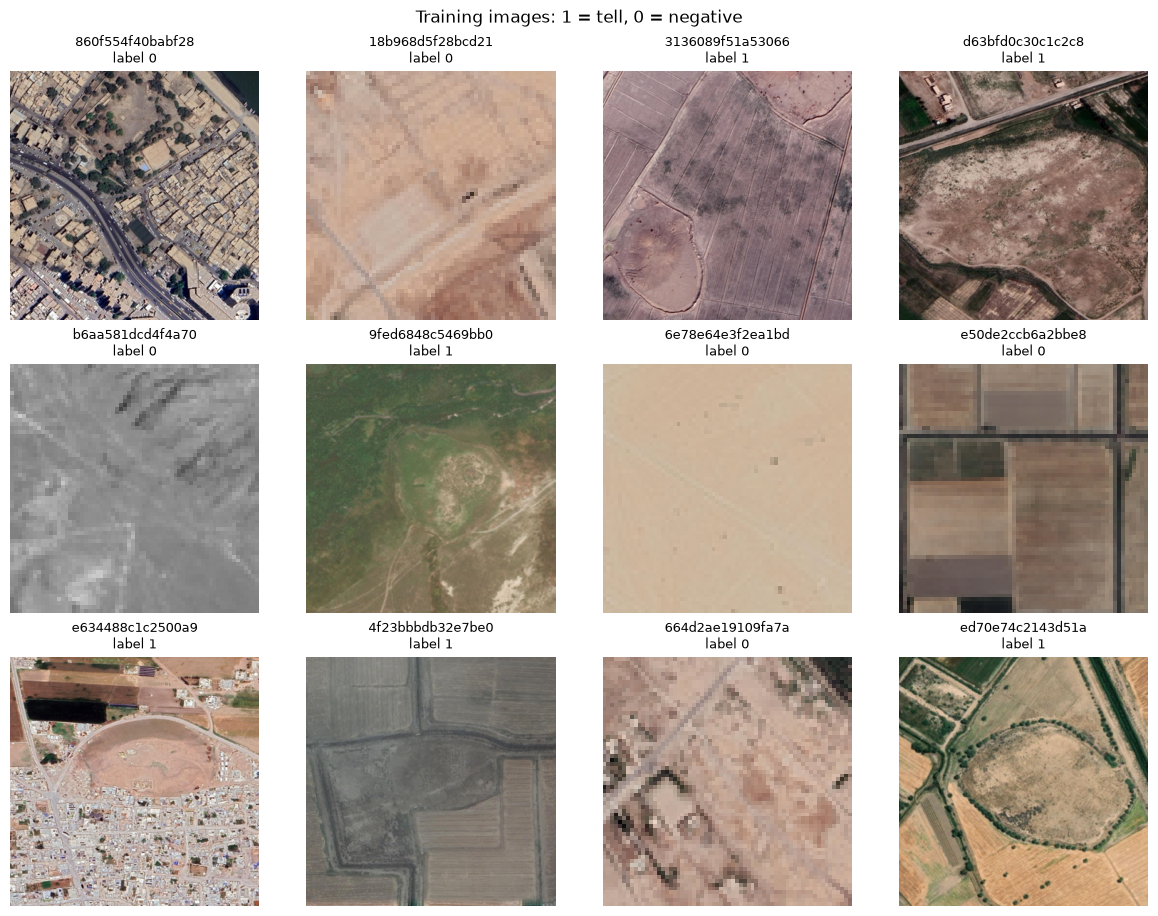

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

archive = workshop.download_enki_sample(assets / "sample_manifest.json", ROOT / "enki_workshop_sample.zip")
images = workshop.index_enki(archive, ROOT / "images")
images, duplicate_audit, audit = workshop.deduplicate_images(images)
splits = workshop.workshop_split(images, per_class=100)
train, validation, test = (splits[name] for name in ("train", "validation", "test"))
print(f"{audit['raw_images']} images → {len(images)} after filtering.")
display(pd.Series({name: len(part) for name, part in splits.items()}, name="tiles").to_frame())
size_counts = images.groupby(["label", "width", "height"]).size().rename("images").reset_index()
print("Original dimensions by source label (0 = negative, 1 = tell):")
display(size_counts)
audit["native_size_counts"] = size_counts.to_dict("records")
audit["image_preprocessing"] = workshop.IMAGE_PREPROCESS_ID
print(f"Both feature pipelines use the same {workshop.COMMON_IMAGE_SIZE} × "
      f"{workshop.COMMON_IMAGE_SIZE} input grid. Preview below shows the original images.")
workshop.contact_sheet(train.sample(12, random_state=42), title="Training images: 1 = tell, 0 = negative")


**Warm-up: compare one pair from the 12 training images above.** Their captions use
the source labels: `1` for tell, `0` for background.

Choose one of each label. Note the tile IDs and describe one visible difference,
such as a rounded patch, vegetation or blurred edges. Could it help distinguish
tell form, or could it reflect how the images were collected?

The size table establishes an acquisition difference associated with the labels.
A classifier could use the resulting sharpness or texture as a *shortcut* instead
of recognising a mound. The table does not establish which cues a fitted model uses.
Discuss briefly, then continue; no site identification
or written report is required here.

## 2. What makes a useful shortlist?

In a real review, a person opens images to examine possible features. Here we can
evaluate an ordering using labels already supplied by the source: rank the validation
images, take the first 50 and count their positive labels.

- **Precision:** what fraction of the selected images have a positive label?
- **Recall:** what fraction of all available positives were selected?

**The next example uses five invented labels, not images.** The list is already in
an imagined model's score order: `1` means positive, `0` negative. It has no connection
to the training-image grid; there are no images to open or classify for this calculation.

In [3]:
# Supplied labels for a counting exercise; no images are loaded here.
# Position in the list represents position in an imagined model ranking.
# 1 = tell-labelled example; 0 = background-labelled example.
ranked_labels = [1, 1, 0, 1, 0]


**What does "take the first two" mean?** Select the first two entries of
`[1, 1, 0, 1, 0]`. That gives the shorter list `[1, 1]`.

Count three things:

1. There are **2 entries** in the shorter list.
2. Both are `1`, so it contains **2 positives**.
3. The complete five-entry list contains **3 positives**.

Therefore, precision is `2 / 2 = 100%`: both selected entries are positive.
Recall is `2 / 3 ≈ 67%`: the selection includes two of the three positives available.

Run the next cell to carry out these same counts. `k` is the number of list entries
to include. Python's `[:k]` takes that many entries from the beginning, and `sum()`
counts the `1`s by adding the labels together.

In [4]:
k = 2  # Number of list entries to include in the shortlist

shortlist_labels = ranked_labels[:k]

shortlist_size = len(shortlist_labels)
positives_in_shortlist = sum(shortlist_labels)
positives_in_full_list = sum(ranked_labels)

precision = positives_in_shortlist / shortlist_size
recall = positives_in_shortlist / positives_in_full_list

print("Full supplied list:", ranked_labels)
print(f"Shortlist (first {k} entries):", shortlist_labels)
print(f"Precision: {positives_in_shortlist}/{shortlist_size} = {precision:.1%}")
print(f"Recall: {positives_in_shortlist}/{positives_in_full_list} = {recall:.1%}")


Full supplied list: [1, 1, 0, 1, 0]
Shortlist (first 2 entries): [1, 1]
Precision: 2/2 = 100.0%
Recall: 2/3 = 66.7%


**Try a larger selection.** Before rerunning, predict the fractions for `k = 4`.
The selected entries are `[1, 1, 0, 1]`. Count their `1`s, then divide by **4** for
precision and by **3** (all positives in the full list) for recall.

Change `k = 2` to `k = 4`, run the cell and explain why the two fractions change
differently. This uses only the supplied labels, not new image judgements.

Section 3 applies the same calculation to actual model rankings at `k = 50`.
We will choose the model that puts more source positives into that fixed shortlist.

## 3. Compare two models

We now return to the **actual Enki images** split in section 1. Our question is:
**which of two ways of describing an image helps us put more tell-labelled examples
into a 50-image shortlist?** Run the cells below in order. They prepare the image
descriptions, train two classifiers, score the validation images and compare the results.

### 3.1. Turn each image into a row of numbers

The classifier used here takes numbers as input. A **feature** is one number describing
an image, such as its average red intensity. A **feature vector** is the whole list of
numbers for one image; a **feature matrix** stacks those lists, with one image per row
and one feature per column. A source label (`1` or `0`) is kept separately: it is the
answer we want the classifier to learn to predict.

We give the same images two different numerical descriptions, also called representations:

| Name in the code | What describes one image? | Where do the numbers come from? |
|---|---|---|
| `colour_texture` | `68` measurements of colour distributions, average colour, variation, and edge strength and direction. | Fixed calculations on the image pixels. This is our simple baseline: a reference against which to judge the more complex representation. |
| `dinov2` | `384` numbers describing visual patterns. This vector is also called an embedding. | A pretrained neural network converts the image into features. Individual numbers do not have simple names such as “mound height” or “probability of a tell”. |

**Pretrained** means DINOv2 learned visual representations before this workshop, on a
large image collection without human-provided training labels. ([DINOv2 documentation](https://github.com/facebookresearch/dinov2))
We keep that encoder **frozen**: its learned parameters do not change when we use our
Enki labels. Its vectors have already been computed and bundled in
`enki_embeddings.npz`, so this notebook loads them without running or training the
neural network. No GPU is needed for this path.

Both branches start with the same 64 × 64 RGB image. The DINO cache was rebuilt
after this correction; the loader rejects old preprocessing versions and changed
image pixels. The displayed original images can contain detail the model never sees.

Both representations will feed the **same kind of classifier: logistic regression**.
We train a separate classifier for each. The comparison is therefore simple image
measurements plus logistic regression versus DINOv2 features plus logistic regression.
The question is whether the pretrained representation contains useful distinctions
that our simple colour and edge summaries miss. The validation results will tell us
whether that helps with this particular labelled sample.

Run the next cell to prepare both feature matrices. `partition_features` puts their
rows into the training, validation and test groups already defined in section 1,
matching image IDs so each row stays aligned with its label. Preparing these fixed
descriptions does not fit a classifier or use the held-out labels. In the summary,
`200` training images and `68` features means a matrix with `200` rows and `68` columns;
it does not mean we have 68 images.

In [5]:
# Compute simple measurements and load the previously computed DINOv2 vectors.
colour_features = workshop.handcrafted_features(images.path)
dino_features = workshop.load_embedding_cache(images, assets / "enki_embeddings.npz")

# Reuse the same image groups for both representations.
feature_sets = {
    "colour_texture": workshop.partition_features(images, colour_features, splits),
    "dinov2": workshop.partition_features(images, dino_features, splits),
}

feature_summary = []
for name, features in feature_sets.items():
    feature_summary.append({
        "representation": name,
        "training_images": features["train"].shape[0],
        "validation_images": features["validation"].shape[0],
        "features_per_image": features["train"].shape[1],
    })
display(pd.DataFrame(feature_summary))


Colour and texture features:   0%|          | 0/593 [00:00<?, ?it/s]

,representation,training_images,validation_images,features_per_image
0,colour_texture,200,119,68
1,dinov2,200,119,384


### 3.2. Learn from the training labels

**Logistic regression** is a classification method despite its name. It learns weights
for the features and an offset, then converts their combination into a score between
`0` and `1` for label `1`. We fit one classifier per representation on the same
training images and labels. Validation will choose between them; test remains reserved.

Each classifier is a **pipeline** with two fitted steps:

1. `StandardScaler` subtracts each feature's training mean and divides by its training
   standard deviation, putting measurements on comparable scales.
2. Logistic regression learns weights from those scaled training rows and their labels.

The pipeline saves the training means and scales and reuses them for later images.
It does not fit either step on validation or test data.

Both models use `C=1`, which controls the penalty on large weights; smaller values
apply a stronger penalty. `class_weight="balanced"` gives classes equal total weight,
which makes no difference to our already balanced training set. `max_iter=2000`
limits optimisation iterations. See the [scaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
and [classifier](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
references for the remaining options.

Run the next cell: `.fit(training_features, training_labels)` learns each pipeline,
and `models` stores it. The classifiers use all 68 or 384 features. Optional lab A
later projects those features into 2D or 3D without changing these classifiers.

In [6]:
models = {}

for name, features in feature_sets.items():
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1, class_weight="balanced", max_iter=2000, random_state=42),
    )
    model.fit(features["train"], train.label)
    models[name] = model
    print(f"Fitted {name}: {len(train)} training images, "
          f"{features['train'].shape[1]} features per image.")


Fitted colour_texture: 200 training images, 68 features per image.
Fitted dinov2: 200 training images, 384 features per image.


### 3.3. Score images the classifiers were not fitted on

Each pipeline receives **validation features only**. `predict_proba` returns two
columns, for labels `0` and `1`; `[:, 1]` takes the second column for every image.
The source labels are attached afterwards for evaluation.

Higher scores mean **inspect earlier**. Although these are probability estimates,
a score of `0.9` has not been established as a 90% chance of archaeology in a new
survey. We rank images rather than apply a `0.5` cutoff.

Run the next cell. It keeps both full rankings and displays the **four highest-scoring
images per model**, colour/texture followed by DINOv2. Read each row left to right;
captions give rank, score and tile ID, and the tables include source labels. These
four-image previews are not the 50-image shortlists used in the next calculation.

colour_texture: first 4 of 119 ranked validation images


,rank,tile_id,score,label
0,1,a24b81d1ae8304bb,0.999649,1
1,2,56ec75dab4ca848c,0.999179,1
2,3,5954a6ad4a0d6090,0.995957,1
3,4,92811badf71adc64,0.995102,1


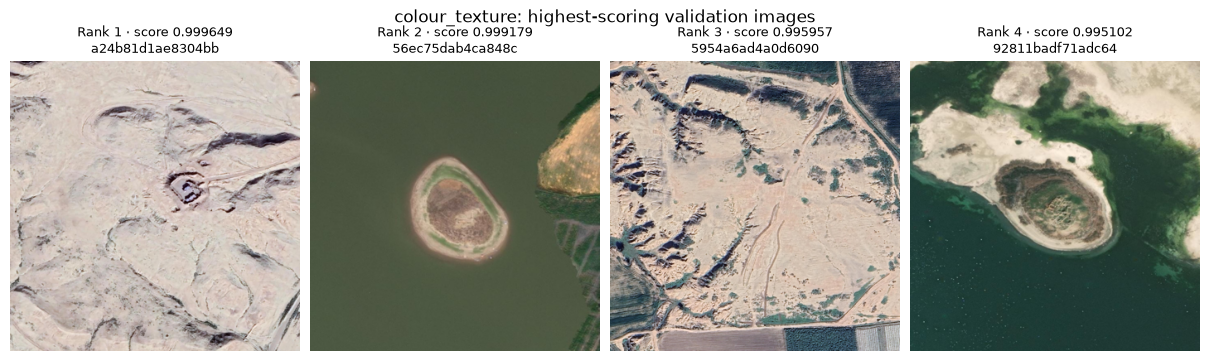

dinov2: first 4 of 119 ranked validation images


,rank,tile_id,score,label
0,1,68f61a3d6c924d82,0.999999,1
1,2,389340306d0485f0,0.999998,1
2,3,6f977f14c9c14d30,0.999998,1
3,4,73ffa72f53708c78,0.999996,1


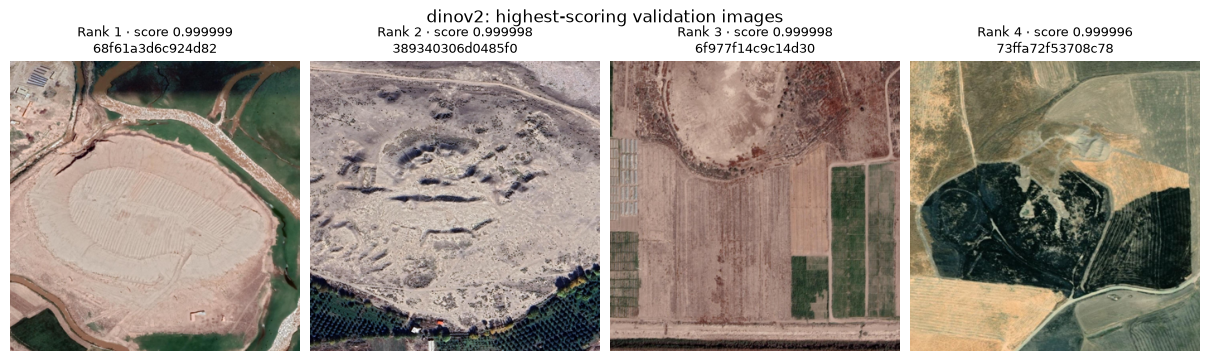

In [7]:
validation_scores = {}

for name, model in models.items():
    probabilities = model.predict_proba(feature_sets[name]["validation"])
    validation_scores[name] = probabilities[:, 1]  # Column for source label 1

# Show each model's highest-scoring images, keeping both full rankings.
validation_rankings = {}
for name, scores in validation_scores.items():
    ranking = validation[["tile_id", "label", "path"]].copy()
    ranking["score"] = scores
    ranking = ranking.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
    ranking.insert(0, "rank", np.arange(1, len(ranking) + 1))
    validation_rankings[name] = ranking
    preview = ranking.head(4)
    print(f"{name}: first {len(preview)} of {len(validation)} ranked validation images")
    display(preview[["rank", "tile_id", "score", "label"]].round(6))

    fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
    for ax, row in zip(axes, preview.itertuples(index=False)):
        ax.imshow(plt.imread(row.path))
        ax.set_title(f"Rank {row.rank} · score {row.score:.6f}\n{row.tile_id}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{name}: highest-scoring validation images")
    plt.show()

# Section 3.4's short exercise still uses the colour/texture ranking.
ranking_example = validation_rankings["colour_texture"]


### 3.4. Count positives in each shortlist and choose a model

We now apply section 2's fractions to the real validation rankings. Our budget is
50 images per model. Complete the two expressions below **before** running the comparison.

The resulting table uses these columns:

| Column | Meaning |
|---|---|
| `model` | The representation used by the fitted classifier. |
| `hits` | Source-positive tiles among the first 50, not newly discovered sites. |
| `reviewed` | Number of images selected by the simulated budget. |
| `precision_at_k` | `hits / reviewed`. |
| `recall_at_k` | `hits / all_validation_positives`. |
| `AP` | Average precision: how well positives are placed throughout the full ranking. |

**Selection rule:** higher recall at 50 wins; higher AP breaks a recall tie. Because
the images and budget are shared, higher recall here also means more hits and higher
precision. An exact tie in both metrics is resolved by model name for reproducibility,
not stronger evidence.

AP can distinguish rankings with the same number of hits in their first 50 places.
For the untied example `[1, 1, 0, 1, 0]`, average the precisions at the positive ranks:
`(1/1 + 2/2 + 3/4) / 3 ≈ 0.917`. The helper uses scikit-learn's
[AP calculation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html),
including tied scores. No additional AP coding is required.

**Exercise (about 3 minutes):** replace the two `...` expressions with the fractions
for precision and recall. `ranking_example` contains the full colour/texture ranking;
the supplied lines select its first 50 rows and count the positives.

Run your completed cell, then the comparison underneath. Check against its colour/texture
row. If your output says `Ellipsis`, the corresponding `...` is still a placeholder.

In [8]:
shortlist = ranking_example.head(50)
hits = int(shortlist["label"].sum())
reviewed = len(shortlist)
total_positives = int(validation.label.sum())

precision = hits / reviewed  # Fraction of the shortlist that is positive
recall = hits / total_positives     # Fraction of all validation positives included

print("Precision:", precision)
print("Recall:", recall)


Precision: 0.8
Recall: 0.6666666666666666


In [9]:
REVIEW_BUDGET = 50
validation_size = len(validation)
validation_positives = int(validation.label.sum())
print(f"Validation pool: {validation_size} images, {validation_positives} source positives.")
print(f"Shortlist budget: {REVIEW_BUDGET} images per model.")

rows = []
for name, scores in validation_scores.items():
    metrics = workshop.ranking_metrics(validation.label, scores, k=REVIEW_BUDGET)
    row = {"model": name}
    row.update(metrics)
    rows.append(row)

# Higher recall wins; higher AP breaks a recall tie.
results = pd.DataFrame(rows).sort_values(
    ["recall_at_k", "AP", "model"], ascending=[False, False, True],
).reset_index(drop=True)
selected = results.iloc[0]["model"]
display(results.round(3))

for row in results.itertuples(index=False):
    print(f"{row.model}: precision = {row.hits}/{row.reviewed} = {row.precision_at_k:.1%}; "
          f"recall = {row.hits}/{validation_positives} = {row.recall_at_k:.1%}.")

winner, runner_up = results.iloc[0], results.iloc[1]
extra_hits = int(winner["hits"] - runner_up["hits"])
print(f"Selected using validation: {selected}")
if extra_hits > 0:
    print(f"Its shortlist contains {extra_hits} more source positives than {runner_up['model']}, "
          "using the same number of slots.")
elif winner["AP"] > runner_up["AP"]:
    print("Both shortlists contain the same number of positives; higher AP broke the tie.")
else:
    print("Recall and AP tie exactly; model-name order broke the tie, not stronger evidence.")


Validation pool: 119 images, 60 source positives.
Shortlist budget: 50 images per model.


,model,hits,reviewed,precision_at_k,recall_at_k,AP
0,dinov2,47,50,0.94,0.783,0.956
1,colour_texture,40,50,0.80,0.667,0.864


dinov2: precision = 47/50 = 94.0%; recall = 47/60 = 78.3%.
colour_texture: precision = 40/50 = 80.0%; recall = 40/60 = 66.7%.
Selected using validation: dinov2
Its shortlist contains 7 more source positives than colour_texture, using the same number of slots.


### 3.5. Put the result in context

The table needs two reference points:

- **Random selection:** if we selected 50 validation images uniformly at random, each
  positive would have a `50 / number_of_validation_images` chance of being included.
  That fraction is the expected recall. The expected number of hits is that fraction
  times the positive count. This is an average over random selections, not a guarantee
  for one draw or a third trained model.
- **Best possible at this budget:** a 50-image shortlist can contain at most 50 positives.
  If there are 60 positives in the pool, even a perfect ordering reaches only
  `50/60 ≈ 83.3%` recall. The remaining 10 cannot fit. That limit is the **recall ceiling**;
  it explains why 100% precision can coexist with less than 100% recall.

The next cell calculates both references from the current validation set. They concern
this sampled pool and budget, not the unknown rate of archaeological sites in a landscape.

In [10]:
shortlist_size = min(REVIEW_BUDGET, validation_size)
random_recall = shortlist_size / validation_size
random_hits = random_recall * validation_positives
maximum_hits = min(shortlist_size, validation_positives)
recall_ceiling = maximum_hits / validation_positives

print(f"Random selection: {random_hits:.1f} source positives on average in {shortlist_size} slots; "
      f"expected recall = {shortlist_size}/{validation_size} = {random_recall:.1%}.")
print(f"Best possible: {maximum_hits} source positives in {shortlist_size} slots; "
      f"recall ceiling = {maximum_hits}/{validation_positives} = {recall_ceiling:.1%}.")
print(f"Selected model: {int(winner['hits'])} source positives in the shortlist, "
      f"{validation_positives - int(winner['hits'])} outside it.")


Random selection: 25.2 source positives on average in 50 slots; expected recall = 50/119 = 42.0%.
Best possible: 50 source positives in 50 slots; recall ceiling = 50/60 = 83.3%.
Selected model: 47 source positives in the shortlist, 13 outside it.


### 3.6. Check the acquisition shortcut

A deliberately limited reference predicts labels using **only original width and
height**. It learns the positive fraction for each size from the training set, then
scores validation images. It never examines pixels. Its accuracy measures how much
the source collection process reveals about the labels; it is not a candidate model.

The second table evaluates the image models within each original size. The
350 × 350 subset contains both labels, so original dimensions alone cannot separate
them there. Compare its AP with its positive fraction, the usual no-skill reference:
this subset contains many more positives than negatives. AP is left undefined for
the 64 × 64 subset because it has only negatives. Small subsets remain uncertain.

Common resizing reduces the resolution shortcut but cannot prove it removed all
acquisition cues. These diagnostics use validation only; test remains reserved.

In [11]:
validation_audit = workshop.validation_diagnostics(
    train, validation, validation_scores, k=REVIEW_BUDGET)
size_probe = validation_audit.loc[validation_audit.model.eq("source_size_only")]
print("Original-size-only reference (learned on training metadata):")
display(size_probe[["model", "images", "accuracy", "precision_at_k", "recall_at_k", "AP"]].round(3))
print("Image models after common preprocessing, grouped by original dimensions:")
display(validation_audit.loc[validation_audit.model.ne("source_size_only"),
    ["model", "subset", "images", "positives", "positive_fraction", "AP"]].round(3))


Original-size-only reference (learned on training metadata):


,model,images,accuracy,precision_at_k,recall_at_k,AP
0,source_size_only,119,0.924,0.9,0.75,0.87


Image models after common preprocessing, grouped by original dimensions:


,model,subset,images,positives,positive_fraction,AP
1,colour_texture,native_64x64,50,0,0.00,NaN
2,colour_texture,native_350x350,69,60,0.87,0.960
3,dinov2,native_64x64,50,0,0.00,NaN
4,dinov2,native_350x350,69,60,0.87,0.996


**Checkpoint:** explain the selected model's result to a partner using its hit count,
review budget and total positive count. Compare recall with random selection and the
budget ceiling. If the hit counts tie, say what decided the choice.

Keep `selected` for the following sections. Next we inspect actual mistakes, then
ask whether the same fitted pipeline makes sense for different Cyprus images.

## 4. Inspect the shortlist

Section 3 counted the selected model's hits. Now inspect what it included and left out
at the **50-image budget**:

- **False alarm:** a source-negative image (`0`) inside the shortlist.
- **Miss:** a source-positive image (`1`) outside the shortlist.

Ranks 1–50 are included; rank 51 onwards is excluded. A high-scoring positive at rank
51 is still a miss at this budget. As the recall ceiling showed, some misses cannot
be avoided when more positives exist than review slots.

The next cell counts both groups and displays **up to four images per group**, highest
score first, with ranks, scores and IDs. An empty group is reported explicitly;
no false alarms does not mean no misses. These categories refer to the source labels,
not an independent archaeological assessment.

dinov2: 50 images in the shortlist
Inside: 47 source positives, 3 source negatives.
Outside: 13 source positives missed at this budget.
False alarms: source negatives inside the shortlist: 3 images


,rank,tile_id,label,score
26,27,8fe7e5a54e2e4fb8,0,0.999086
40,41,75812702833645a4,0,0.985463
41,42,ed6f73d6e7f94d4c,0,0.985020


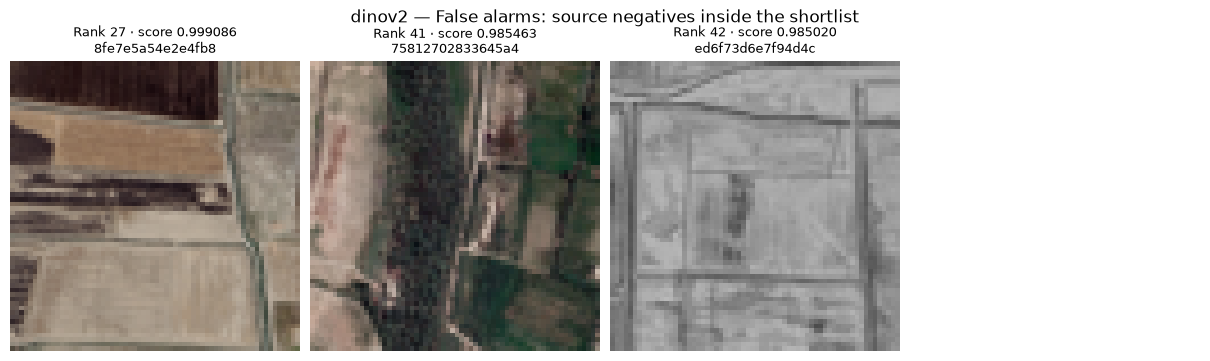

Misses: source positives outside the shortlist: 13 images


,rank,tile_id,label,score
50,51,0dd4324ef7a1c904,1,0.905855
52,53,8bf27fc6264ea16a,1,0.829471
55,56,219122dc13818b57,1,0.745866
56,57,02b728ac4307ec95,1,0.732833


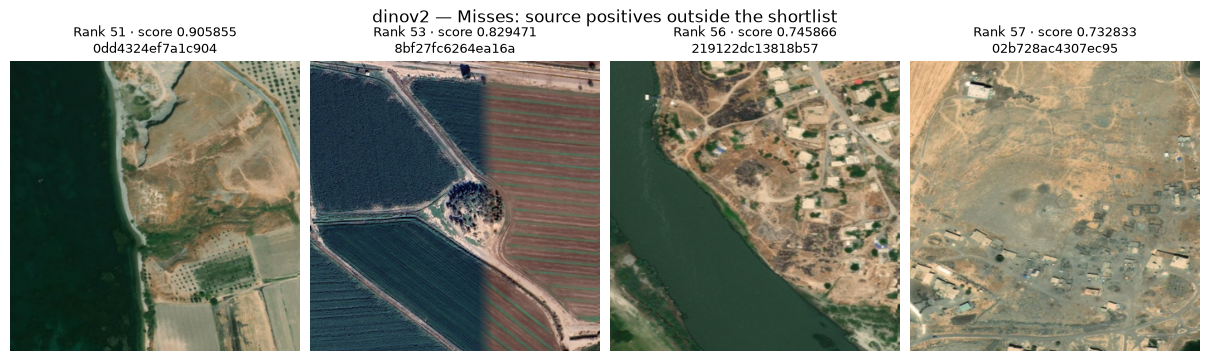

In [12]:
review = validation_rankings[selected].copy()
shortlist = review.head(REVIEW_BUDGET)
false_alarms = shortlist.query("label == 0")
misses = review.iloc[REVIEW_BUDGET:].query("label == 1")

print(f"{selected}: {len(shortlist)} images in the shortlist")
print(f"Inside: {int(shortlist.label.sum())} source positives, {len(false_alarms)} source negatives.")
print(f"Outside: {len(misses)} source positives missed at this budget.")

for title, group in (
    ("False alarms: source negatives inside the shortlist", false_alarms),
    ("Misses: source positives outside the shortlist", misses),
):
    print(f"{title}: {len(group)} images")
    if group.empty:
        print("No examples in this group at this budget.")
        continue

    examples = group.head(4)
    display(examples[["rank", "tile_id", "label", "score"]].round(6))
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout="constrained")
    for ax in axes:
        ax.axis("off")
    for ax, row in zip(axes, examples.itertuples(index=False)):
        ax.imshow(plt.imread(row.path))
        ax.set_title(f"Rank {row.rank} · score {row.score:.6f}\n{row.tile_id}", fontsize=9)
    fig.suptitle(f"{selected} — {title}")
    plt.show()


**Keep one observation for your recommendation.** Choose a displayed tile; use a miss
if there are no false alarms. Record its ID, rank and one visible feature. Distinguish
that observation from a hypothesis about the score, and suggest one comparison that
could test the hypothesis. Uncertainty is a valid observation.

### Exercise: what would ten more reviews recover?

Predict whether ten extra slots will recover ten positives. Then change
**`inspection_budget = 50` to `60`** and run the supplied code. It examines the next
ten images in the same ranking, displays them in a table and shows any newly included
source negatives.

Use the output to explain the trade-off: extra positives recovered, extra negatives
reviewed and positives still missed. Find one of the previously displayed missed tiles
in the added rows if it was recovered.

**Optional five-minute challenge:** find the smallest budget that includes every
source positive. The comparison and report keep the original `REVIEW_BUDGET = 50`;
this is a separate validation experiment.

Extra images reviewed: 10
Extra source positives recovered: 5
Extra background-labelled images: 5
Source positives still outside: 8


,rank,tile_id,label,score
50,51,0dd4324ef7a1c904,1,0.905855
51,52,442d1a796e72e7f3,0,0.885306
52,53,8bf27fc6264ea16a,1,0.829471
53,54,882e3622bf721b63,0,0.815924
54,55,c77ec1cba77e9885,0,0.783404
55,56,219122dc13818b57,1,0.745866
56,57,02b728ac4307ec95,1,0.732833
57,58,fcf88b954d176ba8,0,0.726631
58,59,76d4991d26241476,1,0.694888
59,60,b671ce8300046432,0,0.677887


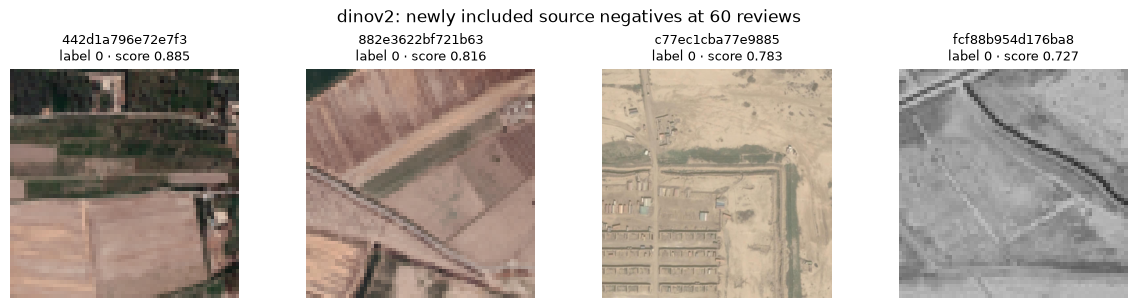

In [13]:
inspection_budget = 60  # Worked example: inspect ten more images.

added = review.iloc[REVIEW_BUDGET:inspection_budget]
remaining_misses = review.iloc[inspection_budget:].query("label == 1")
new_false_alarms = added.query("label == 0")

print(f"Extra images reviewed: {len(added)}")
print(f"Extra source positives recovered: {int(added.label.sum())}")
print(f"Extra background-labelled images: {len(new_false_alarms)}")
print(f"Source positives still outside: {len(remaining_misses)}")
display(added[["rank", "tile_id", "label", "score"]].round(6))
workshop.contact_sheet(new_false_alarms, new_false_alarms.score.to_numpy(), n=4,
                       title=f"{selected}: newly included source negatives at {inspection_budget} reviews")


## 5. Try the same model in Cyprus

We chose a model using Enki validation labels. Now we ask a different question:
**what happens when that fitted model receives images from another setting?**
Applying a model elsewhere is called *transfer*. The selected classifier and its
training scaler are reused unchanged; this cell does not fit a new Cyprus model.
We compare both models' score distributions with Enki validation to expose changes
in their behaviour. The selected model still determines the review order.

### 5.1. Understand the new images and records

The bundle contains **12 Sentinel-2 images**, acquired on **5 August 2024**. Each covers
a 1 km square at 10 m per pixel: a 100 × 100 pixel image. Enlarging the display does
not add detail. Small features may be difficult to distinguish, and a catalogued
settlement need not have the mound form associated with Enki's tell images.
The common 64 × 64 model input is coarser still: about 15.6 m per input pixel here.
Matching pixel dimensions does not match the geographic scale of the Enki crops.

There are six pairs. Each pair contains an image centred on a catalogued settlement
and one centred 2 km to its east, away from catalogue points. `paired_site` identifies
the pair; `tile_id` identifies the individual image.

| Value in `kind` | What it tells us | What it does not tell us |
|---|---|---|
| `catalogued_location` | The image is centred on a settlement recorded in the catalogue. | Whether remains are visible in this image on this date. |
| `unlabelled_background` | The image is centred at a nearby location without a catalogue label. | Whether archaeology is absent. The word `background` in the filename is not a verified negative label. |

Enki supplied image-class labels for counting hits and misses. These Cyprus records
supply **locations and occupation periods**, not equivalent image labels. Several
occupation rows can refer to one settlement. We therefore cannot calculate Cyprus
precision or recall by treating catalogue membership as `1` and its absence as `0`.

Run the next cell. It scores all 12 images with both models, compares their score
ranges with Enki validation, then ranks by the selected model and shows the first
four. The score is the model's response learned from Enki; it has not been validated
as a probability of archaeology in Cyprus. Rank 1 means first among these 12 images.
Sorting uses unrounded scores, even when displayed values look equal. Use this view
to ask what should be investigated, rather than to count discovered sites.

Colour and texture features:   0%|          | 0/12 [00:00<?, ?it/s]

Source-trained scores: these are not calibrated Cyprus probabilities.


,model,group,images,minimum,median,maximum
0,colour_texture,Enki validation negatives,59,0.000007,0.181176,0.951722
1,colour_texture,Enki validation tells,60,0.011063,0.910411,0.999649
2,colour_texture,Cyprus (unlabelled),12,0.999968,1.000000,1.000000
3,dinov2,Enki validation negatives,59,0.000000,0.002753,0.999086
4,dinov2,Enki validation tells,60,0.032733,0.997548,0.999999
5,dinov2,Cyprus (unlabelled),12,0.029189,0.786875,0.974996


,rank,tile_id,kind,paired_site,score
0,1,CY523_site,catalogued_location,CY523,0.974996
1,2,CY5_background,unlabelled_background,CY5,0.888248
2,3,CY1451_site,catalogued_location,CY1451,0.877186
3,4,CY754_site,catalogued_location,CY754,0.829497
4,5,CY479_site,catalogued_location,CY479,0.809706
5,6,CY1451_background,unlabelled_background,CY1451,0.808569
6,7,CY5_site,catalogued_location,CY5,0.765182
7,8,CY523_background,unlabelled_background,CY523,0.634493
8,9,CY71_background,unlabelled_background,CY71,0.514812
9,10,CY479_background,unlabelled_background,CY479,0.431180


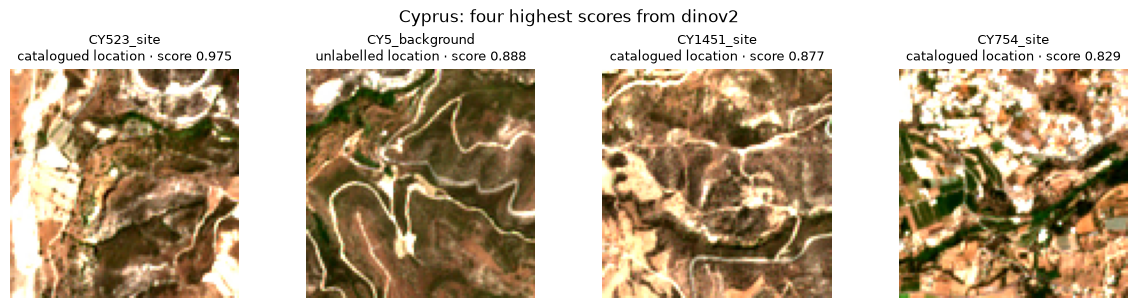

In [14]:
cyprus, cyprus_dino = workshop.load_cyprus(assets)
cyprus_features = {
    "colour_texture": workshop.handcrafted_features(cyprus.path),
    "dinov2": cyprus_dino,
}
cyprus_scores = {}
for name, model in models.items():
    cyprus_scores[name] = model.predict_proba(cyprus_features[name])[:, 1]
    cyprus[f"{name}_score"] = cyprus_scores[name]
transfer_audit = workshop.transfer_summary(validation.label, validation_scores, cyprus_scores)
print("Source-trained scores: these are not calibrated Cyprus probabilities.")
display(transfer_audit.round(6))
cyprus["score"] = cyprus_scores[selected]
cyprus = cyprus.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
cyprus.insert(0, "rank", range(1, len(cyprus) + 1))
display(cyprus[["rank", "tile_id", "kind", "paired_site", "score"]].round(6))
workshop.contact_sheet(cyprus, cyprus.score.to_numpy(), n=4, show_labels=False,
                       title=f"Cyprus: four highest scores from {selected}")


**Read the distribution comparison first.** A shift towards zero or one for the
whole Cyprus sample, or disagreement between the two models, calls the transfer
assumptions into question. Neither direction establishes presence or absence.
The shared preprocessing addresses pixel dimensions; target shape, geographic
scale, rendering, land cover and label meaning still differ. Low scores should not
be repaired by relabelling catalogue locations as visible positives or by fitting
the scaler to these twelve images. A Cyprus model needs suitable local imagery,
expert visibility labels and a separate geographic evaluation set.

### 5.2. Exercise: compare two nearby landscapes

The next cell places the **catalogued location on the left** and its **nearby unlabelled
location on the right**. Allow about 8–10 minutes for both pairs and your notes.

1. Run `pair_id = "CY5"`. Compare scores and ranks, then describe one visible difference.
2. Change only `pair_id` to `"CY479"` and rerun. Does the same kind of location rank first?
   If displayed scores are indistinguishable, say so.
3. In the notes cell, name the tiles, record an observation and explain what evidence
   is missing before either ordering can be called a detection error.

Keep this to two or three sentences for section 6. You do not need to identify remains
from these images. Optional lab C later develops the missing-evidence question into
a study design.

,rank,tile_id,kind,score
6,7,CY5_site,catalogued_location,0.765182
1,2,CY5_background,unlabelled_background,0.888248


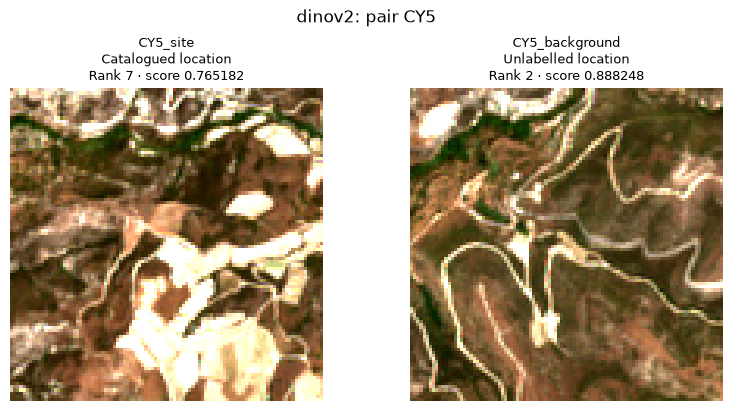

In [15]:
pair_id = "CY5"  # Then change this to "CY479" and rerun.
pair = cyprus.loc[cyprus["paired_site"].eq(pair_id)].sort_values("kind")
display(pair[["rank", "tile_id", "kind", "score"]].round(6))

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, row in zip(axes, pair.itertuples(index=False)):
    place = "Catalogued location" if row.kind == "catalogued_location" else "Unlabelled location"
    ax.imshow(plt.imread(row.path))
    ax.set_title(f"{row.tile_id}\n{place}\nRank {row.rank} · score {row.score:.6f}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{selected}: pair {pair_id}")
plt.show()


**Worked interpretation:** read the current table for `CY5`, then run `CY479`.
State which image ranks higher in each pair and quote the current scores.
In the `CY5` pair, the catalogued image has larger bright angular patches, while the
unlabelled image has winding pale lines through darker terrain; these are observations,
not evidence that the classifier used those features.
Neither ordering establishes a detection error because we lack independent labels
for archaeological features visible in these particular images.

Compare the two models' distributions above. Scores close to either `0` or `1`
are responses of a source-trained classifier, not validated local probabilities.

## Optional lab — choose one before section 6

**Main path:** if time is short, skip this whole block and go to section 6.
The four-hour session reserves about 30 minutes here for **one lab or catch-up**,
not all the extensions. All three choices use the work already completed.

| Choice | Time | Deliverable |
|---|---:|---|
| A. Project the training features | 25–35 min | Complete three expressions; compare the 2D plots and optionally a 3D view. |
| B. Investigate how many labels help | 25–35 min | Run learning curves for both representations; justify a labelling-budget recommendation. |
| C. Design a Cyprus evaluation | 25–30 min | A short study plan with a label definition, sampling plan and decision rule. |

Optional code starts disabled so an uncompleted lab does not stop the main path.
For lab A, complete its function before enabling `RUN_PROJECTION`. For lab B, set
only `RUN_LEARNING_CURVES = True`. For lab C, write notes; no additional code is needed.
Use training/validation evidence only. The original model comparison and the
50-image review budget remain the report's reference result.

### Lab A. See the training features in 2D or 3D

**Question:** do the two source-label groups occupy different parts of feature space?
Allow 25–35 minutes, including interpretation. You have already fitted and compared
the classifiers; this lab visualises their inputs without changing them.

An image has 68 colour/texture values or 384 DINOv2 values. **Principal component
analysis (PCA)** constructs new axes from combinations of these features. PC1 follows
the greatest variation; PC2 captures the most remaining variation at right angles
to PC1. Keeping two or three components gives each image two or three coordinates.
PCA uses feature values, not labels, to choose these directions.

We standardise the **training** features first and fit a separate PCA for each
representation. Every dot will be one of the same 200 training images. Colours and
shapes add the source labels afterwards; validation and test images are excluded.

**Fill the three `...` expressions below:**

1. Select the training matrix for `name` from `feature_sets`.
2. Use `scaler.fit_transform(...)` to scale that matrix.
3. Use `pca.fit_transform(...)` to obtain the projected coordinates.

The returned `explained_variance_ratio_` describes how much feature variation each
axis retains; it is not classification accuracy. See the
[PCA reference](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

Run the completed function cell, set `RUN_PROJECTION = True` and run the supplied
plotting cell. Begin with `N_COMPONENTS = 2`. Until enabled, plotting prints a reminder.

**Instructor copy:** the function is completed and plotting is enabled below.

In [16]:
from sklearn.decomposition import PCA


def project_training_features(name, n_components=2):
    # Step 1: select this representation's training feature matrix.
    X = feature_sets[name]["train"]

    scaler = StandardScaler()
    # Step 2: fit the scaler on X and return the scaled training rows.
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=n_components, svd_solver="full")
    # Step 3: fit PCA on X_scaled and return the projected coordinates.
    coordinates = pca.fit_transform(X_scaled)

    return coordinates, pca.explained_variance_ratio_


colour_texture: coordinate shape (200, 2); variance retained 32.3%.
dinov2: coordinate shape (200, 2); variance retained 22.4%.


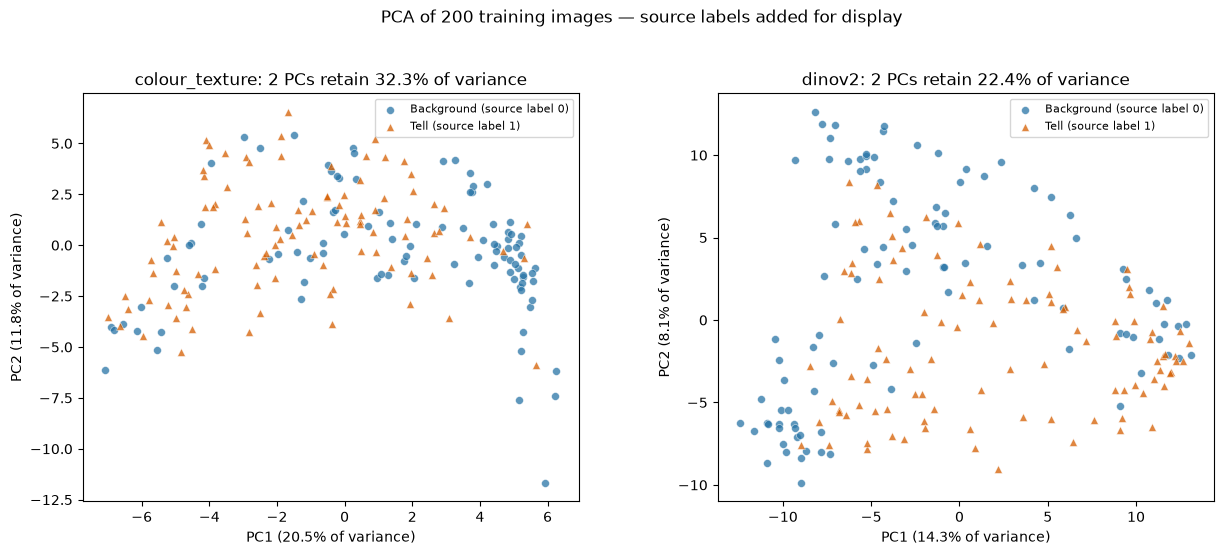

In [17]:
RUN_PROJECTION = True  # Set True after completing and running the function above.
N_COMPONENTS = 2         # Start with 2; change to 3 for the extension.
ELEVATION, AZIMUTH = 20, -60  # Camera angles for the 3D view, in degrees.

if not RUN_PROJECTION:
    print("Complete the three blanks above, run that cell, then set RUN_PROJECTION = True here.")
else:
    if N_COMPONENTS not in (2, 3):
        raise ValueError("Choose N_COMPONENTS = 2 or 3 for this plotting exercise.")

    fig = plt.figure(figsize=(13, 6))
    fig.subplots_adjust(left=0.07, right=0.94, bottom=0.16, top=0.84, wspace=0.28)
    labels = train.label.to_numpy()  # Same row order as the training feature matrices.
    class_styles = [
        (0, "Background (source label 0)", "#2874A6", "o"),
        (1, "Tell (source label 1)", "#D55E00", "^"),
    ]

    for panel, name in enumerate(("colour_texture", "dinov2"), start=1):
        coordinates, variance_ratio = project_training_features(name, N_COMPONENTS)
        ax = fig.add_subplot(1, 2, panel, projection="3d" if N_COMPONENTS == 3 else None)

        for label, description, colour, marker in class_styles:
            points = coordinates[labels == label]
            style = dict(label=description, color=colour, marker=marker,
                         s=32, alpha=0.75, edgecolors="white", linewidths=0.4)
            if N_COMPONENTS == 3:
                ax.scatter(points[:, 0], points[:, 1], points[:, 2], depthshade=False, **style)
            else:
                ax.scatter(points[:, 0], points[:, 1], **style)

        ax.set_xlabel(f"PC1 ({variance_ratio[0]:.1%} of variance)")
        ax.set_ylabel(f"PC2 ({variance_ratio[1]:.1%} of variance)")
        if N_COMPONENTS == 3:
            ax.set_zlabel(f"PC3 ({variance_ratio[2]:.1%} of variance)")
            ax.view_init(elev=ELEVATION, azim=AZIMUTH)
        ax.set_title(f"{name}: {N_COMPONENTS} PCs retain {variance_ratio.sum():.1%} of variance")
        ax.legend(loc="upper right", fontsize=8)
        print(f"{name}: coordinate shape {coordinates.shape}; "
              f"variance retained {variance_ratio.sum():.1%}.")

    fig.suptitle(f"PCA of {len(train)} training images — source labels added for display")
    plt.show()


**Interpret the plots:** describe one region of overlap or separation and record
the retained variance in each panel. Why could a classifier distinguish images that
overlap here? Why is separation among training images not validation performance?

Each panel has its own axes; positions cannot be compared directly between panels.
PCA prioritises variation, which need not be the variation that separates the labels.
The classifiers still use their full feature vectors.

**If time permits:** set `N_COMPONENTS = 3`. Does PC3 reveal structure hidden in 2D?
Inline views may be static: change `AZIMUTH` from `-60` to `30` and rerun to see another
angle. The angle changes apparent overlap, not the underlying data.

After this lab, continue to section 6. Lab B and lab C are alternatives, not prerequisites.

### Lab B. How much does more labelled training data help?

Suppose an expert can label 20 images now or 200 with more effort. Would the extra
labels improve the shortlist equally for both representations? **Predict a pattern
before running**, then allow 25–35 minutes to investigate it.

The supplied helper fits fresh copies of each pipeline with **10, 25, 50 and 100
images per class**: 20, 50, 100 and 200 labelled training images in total. Each size
uses three random subsamples. Every fit uses the same validation pool and 50-image
review budget, so the resulting *learning curve* compares performance as training
data increases. The encoder remains frozen; each scaler and classifier are fitted
on that subsample. The original `models` and `selected` are left intact.

Set `RUN_LEARNING_CURVES = True` and run the next cell. Each point is mean validation
recall across three fits; bars span the lowest to highest recall. They show sensitivity
to training subsamples, **not confidence intervals or variation across regions**.
At 100 per class, every fit uses all the available training images.

**Your task:** recommend a training-label budget for a follow-up experiment. Cite
the gain from the smallest to largest budget and the variation at one intermediate
budget for each representation. Explain what uncertainty this experiment cannot
measure. Do not assume the curves must improve at every step.

,model,labels_per_class,mean_recall,min_recall,max_recall,training_images
0,colour_texture,10,0.506,0.483,0.517,20
1,colour_texture,25,0.600,0.583,0.617,50
2,colour_texture,50,0.622,0.600,0.633,100
3,colour_texture,100,0.667,0.667,0.667,200
4,dinov2,10,0.689,0.667,0.700,20
5,dinov2,25,0.783,0.767,0.800,50
6,dinov2,50,0.750,0.717,0.767,100
7,dinov2,100,0.783,0.783,0.783,200


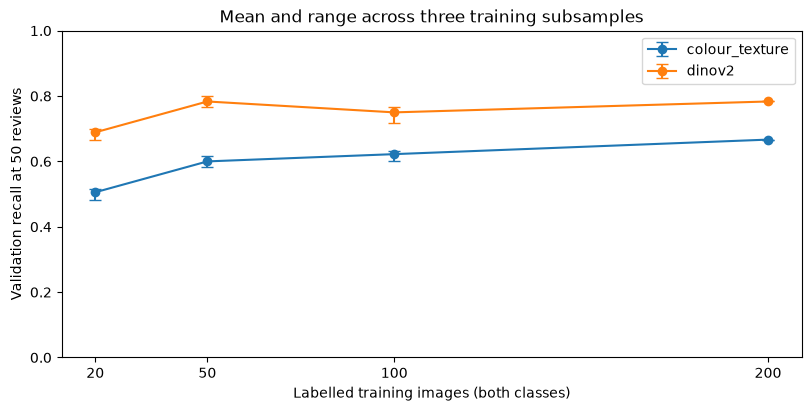

In [18]:
RUN_LEARNING_CURVES = True  # Enable only if you choose lab B.

if not RUN_LEARNING_CURVES:
    print("Lab B skipped. Choose one optional lab, or continue to section 6.")
else:
    learning_rows = []
    for name in ("colour_texture", "dinov2"):
        part = workshop.learning_curve_rows(
            models[name], feature_sets[name]["train"], train.label.to_numpy(),
            feature_sets[name]["validation"], validation.label.to_numpy(),
            workshop.ranking_metrics, REVIEW_BUDGET,
        )
        part["model"] = name
        learning_rows.append(part)
    learning_results = pd.concat(learning_rows, ignore_index=True)
    learning_summary = learning_results.groupby(["model", "labels_per_class"]).agg(
        mean_recall=("recall_at_k", "mean"),
        min_recall=("recall_at_k", "min"),
        max_recall=("recall_at_k", "max"),
    ).reset_index()
    learning_summary["training_images"] = 2 * learning_summary["labels_per_class"]
    display(learning_summary.round(3))

    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    for name, group in learning_summary.groupby("model"):
        spread = np.vstack([group.mean_recall - group.min_recall,
                            group.max_recall - group.mean_recall])
        ax.errorbar(group.training_images, group.mean_recall, yerr=spread,
                    marker="o", capsize=4, label=name)
    ax.set(xlabel="Labelled training images (both classes)",
           ylabel=f"Validation recall at {REVIEW_BUDGET} reviews", ylim=(0, 1))
    ax.set_xticks([20, 50, 100, 200])
    ax.set_title("Mean and range across three training subsamples")
    ax.legend()
    plt.show()


Record your budget recommendation and its evidence in your notes, then go to
section 6. Repeated fits share the same validation set and sometimes overlapping
training images; they are not independent regional evaluations. A flat curve could
reflect this task or the review-budget ceiling, not prove that additional labels
would never help.

**Instructor discussion:** compare the actual means and ranges rather than select a
budget from the smoothness of the lines. A useful answer states the observed recall
gain, identifies a budget whose subsamples vary, and weighs that gain against labelling
effort. Small variation at the full budget is expected because all 200 images are
reused. A recommendation for local data collection still needs a new geographic
evaluation; the curve does not answer the Cyprus transfer question.

**One worked answer for the default data:** from 20 to 200 training images, DINOv2's
mean recall increases from 0.772 to 0.833, while colour/texture increases from 0.506
to 0.667. A pilot could start by investigating 50 DINOv2 training labels: mean recall
is 0.817, with a range of 0.800–0.833 across these subsamples. That saves labelling effort
in this example, but a new geographic assessment is needed before treating it as a
sufficient budget for another survey.

### Lab C. Design a Cyprus evaluation that could change your decision

Allow 25–30 minutes. Write a **half-page study plan**, without downloading new data
or training a model. Combine the missing labels from section 5 with a decision rule:

1. Define the target visible feature and suitable imagery. Give an example for each
   label: visible, not visible in the image, and uncertain. Separate image visibility
   from archaeological presence at a location.
2. Propose how to select new images across areas and the score range. Explain how you
   would detect missed positives; reviewing only high-scoring images is insufficient.
3. Identify who supplies the labels, how disagreements are handled and which locations
   remain separate from model development.
4. Choose a review budget, evaluation metric and minimum acceptable result. Explain
   the trade-off behind your threshold and check that the budget can support it.
   The workshop provides no universal deployment threshold.
5. State a result that would make you revise or abandon the proposed use.

Agree on the rule before seeing the future study's test results. Ask a partner to
find one ambiguity in the plan, then revise it. Reuse the key next step in section 6;
the detailed plan stays in your notebook notes.

**Instructor example of an approach:** define a visible target at a stated image
resolution, obtain independent expert judgements with uncertainty retained, and
sample across scores in several areas. Reserve whole areas for assessment. Report
budgeted precision and recall for that defined target, with unclear cases documented.
The threshold must follow the team's review capacity and consequences of misses;
accept different justified thresholds. “Not visible” is not proof of absence.

## 6. Make a recommendation and export

Bring together the measurement from section 3, an image observation from section 4
or 5, and the limits of transfer. Finish any optional lab first. A recommendation
against deployment is valid if the evidence supports it.

### 6.1. Exercise: write a 4–6 sentence recommendation

Write between the triple quotes in the next cell. Use these five prompts:

1. **Decision:** name the selected model and the use you recommend, with its scope.
2. **Measurement:** cite hits, reviews and available positives, then precision and recall
   from section 3.4. Keep the original 50-image comparison; identify the larger-budget
   experiment separately if you mention it.
3. **Observation:** cite one tile ID and a visible feature, separating observation
   from a possible explanation of its score.
4. **Limitation:** explain why the Cyprus examples do not establish detection accuracy.
5. **Next evidence:** propose suitable local imagery, expert labels and locations
   reserved for independent assessment. Use lab C's proposal if you completed it.

Run the cell to display your text. Exchange it with a partner, or reread it yourself:
can the reader identify the proposed use, its evidence and a claim that still needs
testing? Make one revision if needed, then export. This is the only report to submit;
reuse your earlier notes.

In [19]:
winner = results.loc[results["model"].eq(selected)].iloc[0]
recommendation = (
    f"Evaluate {selected} further as an aid to expert review of imagery similar to Enki. "
    f"On this validation sample it finds {int(winner.hits)} of {int(validation.label.sum())} "
    f"source positives in {int(winner.reviewed)} reviews "
    f"(recall {winner.recall_at_k:.3f}, precision {winner.precision_at_k:.3f}). "
    "Cyprus tile CY5_site shows bright angular patches in the displayed image; "
    "that observation does not establish which cues the classifier used. "
    "Cyprus accuracy remains unknown because catalogue membership is not an image-visibility "
    "label and the other locations are unlabelled. "
    "Common 64-pixel preprocessing reduces the source-size shortcut, but acquisition "
    "differences and geographic independence remain unresolved. "
    "Before field deployment, evaluate representative local imagery with expert visibility "
    "labels and a geographic holdout, using imagery appropriate to the size of the features sought."
)
print(recommendation)


Evaluate dinov2 further as an aid to expert review of imagery similar to Enki. On this validation sample it finds 47 of 60 source positives in 50 reviews (recall 0.783, precision 0.940). Cyprus tile CY5_site shows bright angular patches in the displayed image; that observation does not establish which cues the classifier used. Cyprus accuracy remains unknown because catalogue membership is not an image-visibility label and the other locations are unlabelled. Common 64-pixel preprocessing reduces the source-size shortcut, but acquisition differences and geographic independence remain unresolved. Before field deployment, evaluate representative local imagery with expert visibility labels and a geographic holdout, using imagery appropriate to the size of the features sought.


### 6.2. Save the choice and its evidence

Run the next cell after finishing your recommendation and validation experiments.
It uses the selected model to score the **Enki test images without using their labels**,
then saves the ranking and your current evidence in `team_submission.zip`.

| File in the ZIP | Purpose |
|---|---|
| `submission.csv` | Every test tile's ID, score and rank; no test labels. |
| `configuration.json` | The selected model, settings, sample information and review budget. |
| `validation_results.csv` | The two models' validation results used for selection. |
| `cyprus_review.csv` | Cyprus scores and location metadata, not measured detection outcomes. |
| `data_audit.json` | Duplicate audit, original size/label counts and common preprocessing. |
| `validation_diagnostics.csv` | Size-only reference and validation AP within original dimensions. |
| `transfer_diagnostics.csv` | Both models' score distributions on Enki validation and Cyprus. |
| `recommendation.md` | Your written recommendation. |

This records the current run; it does not lock the notebook or save a fitted model
object. Rerunning export replaces the ZIP with the current results and text.
An empty recommendation produces a draft: finish it and export again before sharing.
Download the ZIP using the link or Colab's Files panel, and save the notebook so your
exercise notes and image observations are preserved too.

In [20]:
test_scores = models[selected].predict_proba(feature_sets[selected]["test"])[:, 1]
submission = workshop.write_submission(test, test_scores, ROOT / "submission.csv")
bundle = workshop.export_results(ROOT, results, cyprus, recommendation, configuration={
    "selected_model": selected, "review_budget": REVIEW_BUDGET,
    "C": models[selected].named_steps["logisticregression"].C,
    "class_weight": "balanced", "scaler": "StandardScaler",
    "training_tiles": len(train), "test_tiles": len(test),
    "sample_manifest_sha256": workshop.file_digest(assets / "sample_manifest.json"),
}, data_audit=audit, validation_audit=validation_audit, transfer_audit=transfer_audit)
display(submission.head())
display(FileLink(str(bundle)))
print("Saved:", bundle, "— in Colab, download it from the Files panel.")


,tile_id,score,rank
0,136c8fb5b0b33e74,0.999997,1
1,f76b1ac041854f4f,0.999994,2
2,c7c369149d1f39ab,0.999992,3
3,e8af80b1ba5f361e,0.999984,4
4,fe336ee05755bbef,0.999984,5


/Users/orbitfold/Programming/archaeology-challenge/archaeology-challenge/.work/instructor_execution/archaeology_workshop/team_submission.zip

Saved: archaeology_workshop/team_submission.zip — in Colab, download it from the Files panel.


### 6.3. Final reveal — after sharing your recommendation

Validation helped choose the model. The reserved **Enki test set** now assesses that
saved choice; using its result to choose another model would turn it into development
data. The Cyprus images are not part of this test.

The participant copy leaves `REVEAL_TEST = False` until the debrief. This instructor
copy sets it to `True` to display the worked result. The cell matches saved scores to
the test source labels and uses the original review budget.

Compare the test counts and recall with validation and random ordering. Which limitation
from the recommendation still applies? A strong result does not establish geographic
independence or Cyprus performance. Stop model experiments after this reveal.

In [21]:
REVEAL_TEST = True
if REVEAL_TEST:
    final_result = workshop.score_submission(submission, test, workshop.ranking_metrics, REVIEW_BUDGET)
    display(pd.Series(final_result, name="final_test").round(3).to_frame())
    print(f"Found {int(final_result['hits'])} of {int(test.label.sum())} source positives "
          f"in {int(final_result['reviewed'])} test-image reviews.")
    print(f"Random ordering: expected recall {min(REVIEW_BUDGET, len(test)) / len(test):.3f}.")
else:
    print("Test labels remain unused. Finish and share your recommendation before the reveal.")


,final_test
hits,48.000
reviewed,50.000
precision_at_k,0.960
recall_at_k,0.800
AP,0.961


Found 48 of 60 source positives in 50 test-image reviews.
Random ordering: expected recall 0.420.


### Instructor discussion notes

- **Shortlist example:** this is arithmetic on supplied labels, not an image-review
  task. No images are displayed or judged here; the list is unrelated to the earlier
  training-image grid. At `k=2`, select `[1, 1]`: precision is 2/2 (100%) and recall
  is 2/3 (about 67%). At `k=4`, select `[1, 1, 0, 1]`: they are 3/4 (75%) and
  3/3 (100%). The extra entries are `0` and `1`, so recall rises while precision
  falls. The denominators refer to the selection size and the total positive count.
- **Model comparison:** distinguish feature extraction from classifier fitting. The
  colour/texture vector has 68 measurements; the cached DINOv2 vector has 384 values.
  Each gets a separately fitted scaler and logistic regression using the same training
  images and labels. DINOv2 stays frozen. Validation labels enter the evaluation after
  prediction, not the classifier fit. Test results must not choose the representation.
- **Optional lab A:** complete the participant function with the training matrix,
  `scaler.fit_transform(X)`, then `pca.fit_transform(X_scaled)`. Fit on training
  features only; labels supply plot colours, not PCA directions. Compare both
  representations in 2D and optionally 3D, including the variance retained.
  PCA axes differ between panels, and overlap can hide separation in omitted
  dimensions. Visual separation is not validation performance. The classifiers
  still use their full feature vectors; the projection is only for exploration.
- **Short exercise:** precision is `hits / reviewed`; recall is
  `hits / total_positives`. Have learners calculate these from the ranking before
  displaying the comparison table, then check against its colour/texture row.
- **Model choice:** use the actual counts printed in section 3. Higher recall at 50
  wins; AP describes the full ranking and breaks a recall tie. Equal hits mean neither
  shortlist finds more positives at this budget. The name breaks an exact metric tie
  without establishing a superior model. Compare against expected random recall and
  the budget ceiling. A strong baseline can reflect useful information or shortcuts;
  performance alone cannot tell us which.
- **Mistakes:** use the displayed ranks to explain inclusion at the review budget.
  Zero false alarms can coexist with missed positives; do not invent an empty group's
  examples. Ask for a tile ID and a visible observation before accepting an explanation.
  The sample recommendation cites the displayed Cyprus pair.
- **Resolution audit:** the original image sizes predict labels surprisingly well.
  Both models now use a common 64 × 64 input; the DINO cache was regenerated.
  Compare within-size AP with positive fraction. This is a diagnostic of remaining
  acquisition bias, not a geographic evaluation or proof that all shortcuts vanished.
- **Budget experiment:** read the actual added positives, negatives and remaining
  misses after increasing the budget from 50 to 60. Find the last positive's rank
  for the optional all-positives question. This
  experiment does not change `REVIEW_BUDGET` or the reported model comparison.
- **Cyprus pairs:** participants change one pair ID, from `CY5` to `CY479`, and compare
  the two landscapes. Use the current scores to describe the order. Ask for IDs and an observation,
  then the missing image-visibility labels. Neither ordering establishes an error.
  Compare both models' score distributions; extremes do not establish archaeological presence.
  For the extension, sample across scores and regions, retain uncertain judgements,
  and reserve separate locations for assessment. Catalogue absence is not a negative label.
- **Recommendation:** use five prompts: decision, measured evidence, image observation,
  limitation and next study. Accept a recommendation against deployment. Keep the
  original 50-image comparison distinct from the larger-budget experiment. The sample
  report uses six sentences and the currently selected model's validation row.
  Lab C combines the evaluation design and decision-rule extensions.
- **Export and debrief:** the ZIP records the current run; rerunning export replaces it.
  Share the recommendation before the reveal. The test cell scores the saved ranking
  against Enki source labels, not Cyprus labels. Discuss the comparison with validation
  and random ordering without selecting again on test performance. Neither a strong
  nor a weak test result resolves the missing geographic or Cyprus evidence.

Choose only one optional lab at the block before section 6, or use that time for
catch-up. The instructor copy runs both computational labs for reference. Model
extraction and live imagery acquisition belong in preparation, outside class.

### Data and credits

- **Enki:** [Rosati (2025)](https://zenodo.org/records/14950565), a curated 600-image sample
  from `Normalized_Tell_combined_350.zip` (whole-archive MD5 `1d4ea398ea5669f9bca4539416847206`).
  Member CRCs and decoded-pixel hashes verify the partial download. Five RGB positive
  categories are used; masked and black-and-white folders are excluded.
  The source declares CC BY-SA 4.0 and separate Google/Bing imagery conditions; retain its notices.
- **Cyprus catalogue:** [Crawford & Vella (2022)](https://doi.org/10.5334/joad.96), CC BY 4.0;
  [source revision](https://github.com/K-A-Crawford/Cyprus_Settlements/tree/70a5c3d399a2451e1d8dd5eb947eb80055276b44).
  There are 8,766 occupation rows and 1,559 settlement IDs.
- **Image features:** [DINOv2](https://github.com/facebookresearch/dinov2),
  `facebook/dinov2-small`, revision `ed25f3a31f01632728cabb09d1542f84ab7b0056`.
  Enki and Cyprus use full-frame bicubic resizing to 64 × 64 before DINO's 224 × 224
  input, ImageNet normalization and L2 normalization. Both caches bind image IDs to
  decoded-pixel hashes, pinned weights and the preprocessing version.
- **Cyprus imagery:** modified Copernicus Sentinel data (2024), via
  [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a).
  Scene `S2A_MSIL2A_20240805T082601_R021_T36SVD_20240805T144559`.
  The [Sentinel-2 band specifications](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data/S2L2A.html)
  give 10 m sampling for the visible bands used here.
  Nearby centres are 2 km east and at least 750 m from catalogue points; chips have at least
  90% clear-land pixels. Acquisition details are in `assets/cyprus/provenance.json`.

**If a download fails:** use the facilitator's sample ZIP at the path given at the start;
do not rename the full source archive to that filename. After restarting the kernel, rerun
from the top. In Colab, download your outputs before the runtime ends.